# NHANES: comparing three models and the final test

This notebook trains and compares the three pre-registered algorithms on the NHANES Tier 3 features, selects one with the pre-registered rule, and evaluates it **once** on the test set. It follows Section 6 of `documentation/preregistration.md`:

- same split (saved by the EDA notebook), same preprocessing pipeline, same 5 folds, same primary metric (F2) for all three models
- decision threshold tuned for F2 inside the training folds
- model selection on cross-validation results only
- the test set is used once, in section 8, after the model is chosen

Output: `models/ckd_screening_pipeline.joblib` (the full preprocessing and model pipeline used by the app) and `models/model_card.json` (its settings and results).

## 1. Setup

Only the 13 columns in `nhanes.FEATURES` are given to the models. The label columns in the file (`egfr`, `URDACT`, `low_egfr`, `albuminuria`) are kept aside for the error analysis.

In [1]:
import json
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))

import modeling
import nhanes
import plot_style

plot_style.apply()
FIGURE_DIR = PROJECT_ROOT / "documentation" / "figures"
MODEL_DIR = PROJECT_ROOT / "models"

data = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "nhanes_cohort.csv")
train = data[data["split"] == "train"].reset_index(drop=True)
test = data[data["split"] == "test"].reset_index(drop=True)

X_train, y_train = train[nhanes.FEATURES], train["ckd"]
X_test, y_test = test[nhanes.FEATURES], test["ckd"]
print(f"train: {X_train.shape}, CKD {y_train.mean():.1%}")
print(f"test:  {X_test.shape}, CKD {y_test.mean():.1%}")

train: (5890, 13), CKD 16.5%
test:  (1473, 13), CKD 16.5%


## 2. Baselines

Two simple rules, scored on the same 5 validation folds as the models. Neither counts as one of the three models.

1. **Refer everyone.** The floor. A model that cannot beat it is not useful.
2. **Risk-factor rule.** Refer if the person has diabetes, has been told of high blood pressure, has heart disease or stroke, or is 60 or older. This is roughly what a health worker would already do without a model. A missing answer counts as not meeting that part of the rule.

In [2]:
def risk_factor_rule(X):
    rule = (X["diabetes"] == "yes") | (X["told_htn"] == 1) | (X["any_cvd"] == 1) | (X["age"] >= 60)
    return rule.astype(int)

baselines = {
    "Refer everyone": modeling.cross_validate_rule(pd.Series(1, index=X_train.index), y_train),
    "Risk-factor rule": modeling.cross_validate_rule(risk_factor_rule(X_train), y_train),
}
modeling.summarize(baselines)[["f2 mean", "f2 sd", "recall mean", "specificity mean", "precision mean"]].round(3)

,f2 mean,f2 sd,recall mean,specificity mean,precision mean
Refer everyone,0.498,0.001,1.000,0.000,0.165
Risk-factor rule,0.576,0.019,0.841,0.514,0.255


**Finding:** Referring everyone gives F2 = 0.498, the floor worked out in the EDA. The risk-factor rule is much better: F2 = 0.576, catching 84.1% of CKD cases while leaving 51.4% of people without CKD un-referred. This rule is a strong baseline. It already uses the four strongest signals from the EDA (age, diabetes, hypertension, heart disease).

**Action:** a model is only worth deploying if it does better than the risk-factor rule, not just better than referring everyone.

## 3. Tuning the three models

For each algorithm, `modeling.tune` runs a grid search over a small set of hyperparameters (listed in `modeling.make_models`), scored by F2 on the 5 shared folds. Inside every fit, `TunedThresholdClassifierCV` picks the F2-best decision threshold with its own inner cross-validation, so the threshold is never chosen on the data it is scored on.

`modeling.cross_validate_model` then refits the best settings on each of the 5 folds and records every metric, plus an out-of-fold probability for each training person (a prediction from a model that never saw that person). This cell takes several minutes.

In [3]:
preprocessor = modeling.make_preprocessor(nhanes.NUMERIC_FEATURES, nhanes.BINARY_FEATURES, nhanes.CATEGORICAL_FEATURES)

searches, fold_scores, oof_proba, oof_pred = {}, {}, {}, {}
for name, (model, grid) in modeling.make_models().items():
    start = time.time()
    searches[name] = modeling.tune(preprocessor, model, grid, X_train, y_train)
    fold_scores[name], oof_proba[name], oof_pred[name] = modeling.cross_validate_model(
        searches[name].best_estimator_, X_train, y_train)
    best = {k.replace("estimator__model__", ""): v for k, v in searches[name].best_params_.items()}
    print(f"{name}: best {best}, mean F2 {fold_scores[name]['f2'].mean():.3f}, {time.time() - start:.0f} s")

Logistic Regression: best {'C': 0.01}, mean F2 0.578, 46 s


Random Forest: best {'max_depth': None, 'min_samples_leaf': 20}, mean F2 0.580, 135 s


Gradient Boosting: best {'learning_rate': 0.1, 'max_depth': 3, 'max_iter': 100}, mean F2 0.580, 165 s


## 4. Cross-validation results

Mean and standard deviation across the 5 validation folds, for all three models and both baselines. These are **validation results**. The test set has not been used.

In [4]:
summary = modeling.summarize({**fold_scores, **baselines})
summary.to_csv(MODEL_DIR / "cv_results.csv")

table = pd.DataFrame(index=summary.index)
for metric in modeling.METRICS:
    table[metric] = summary[f"{metric} mean"].map("{:.3f}".format) + " +/- " + summary[f"{metric} sd"].map("{:.3f}".format)
table["mean threshold"] = [fold_scores[n]["threshold"].mean().round(3) if n in fold_scores else "" for n in table.index]
table

,f2,recall,precision,specificity,f1,accuracy,roc_auc,pr_auc,brier,mean threshold
Logistic Regression,0.578 +/- 0.027,0.793 +/- 0.033,0.278 +/- 0.017,0.591 +/- 0.024,0.411 +/- 0.022,0.624 +/- 0.023,0.758 +/- 0.014,0.411 +/- 0.023,0.198 +/- 0.006,0.427
Random Forest,0.580 +/- 0.014,0.819 +/- 0.025,0.269 +/- 0.021,0.554 +/- 0.059,0.404 +/- 0.022,0.598 +/- 0.046,0.770 +/- 0.012,0.419 +/- 0.019,0.183 +/- 0.004,0.361
Gradient Boosting,0.580 +/- 0.023,0.791 +/- 0.053,0.282 +/- 0.011,0.599 +/- 0.036,0.415 +/- 0.013,0.631 +/- 0.024,0.760 +/- 0.014,0.408 +/- 0.016,0.184 +/- 0.004,0.366
Refer everyone,0.498 +/- 0.001,1.000 +/- 0.000,0.165 +/- 0.000,0.000 +/- 0.000,0.284 +/- 0.001,0.165 +/- 0.000,nan +/- nan,nan +/- nan,nan +/- nan,
Risk-factor rule,0.576 +/- 0.019,0.841 +/- 0.029,0.255 +/- 0.011,0.514 +/- 0.023,0.392 +/- 0.015,0.568 +/- 0.019,nan +/- nan,nan +/- nan,nan +/- nan,


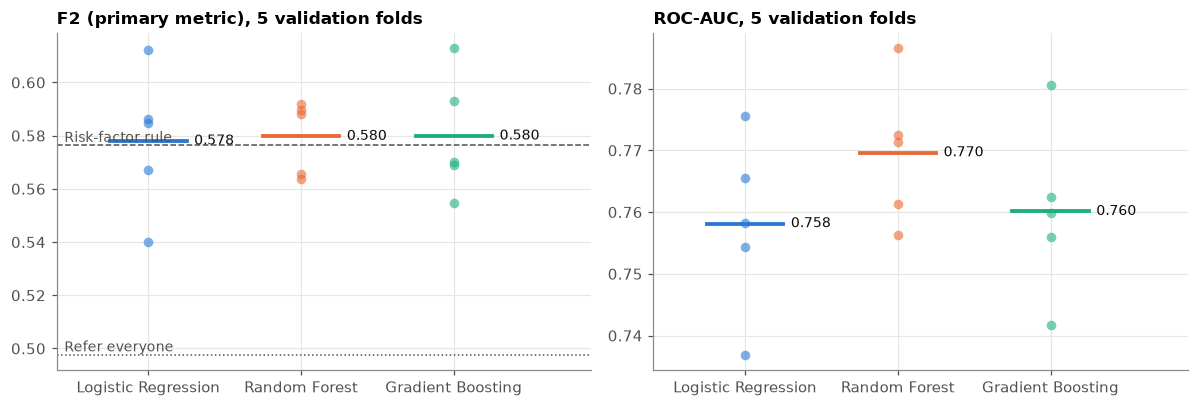

In [5]:
model_colors = {"Logistic Regression": plot_style.NO_CKD, "Random Forest": plot_style.CKD, "Gradient Boosting": "#1baf7a"}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, metric, title in zip(axes, ["f2", "roc_auc"], ["F2 (primary metric)", "ROC-AUC"]):
    for i, (name, color) in enumerate(model_colors.items()):
        values = fold_scores[name][metric]
        ax.scatter(np.full(len(values), i), values, color=color, s=40, alpha=0.6, linewidths=0)
        ax.plot([i - 0.25, i + 0.25], [values.mean()] * 2, color=color, linewidth=2.5)
        ax.text(i + 0.3, values.mean(), f"{values.mean():.3f}", va="center", fontsize=9, color=plot_style.TEXT)
    ax.set_xticks(range(3), list(model_colors), rotation=0)
    ax.set(title=f"{title}, 5 validation folds", xlim=(-0.6, 2.9))
for name, style in [("Refer everyone", ":"), ("Risk-factor rule", "--")]:
    level = baselines[name]["f2"].mean()
    axes[0].axhline(level, color=plot_style.TEXT_SECONDARY, linestyle=style, linewidth=1)
    axes[0].text(-0.55, level, name, ha="left", va="bottom", fontsize=9, color=plot_style.TEXT_SECONDARY)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "nhanes_08_cv_comparison.png")
plt.show()

**Finding:** The three models are almost identical. Mean F2 is 0.578 (Logistic Regression), 0.580 (Random Forest) and 0.580 (Gradient Boosting), and the fold-to-fold spread (SD 0.014 to 0.027) is several times larger than the differences between them. ROC-AUC is 0.758 to 0.770, which means a randomly chosen CKD patient gets a higher score than a randomly chosen non-CKD person about 76 to 77% of the time. Random Forest has the highest ROC-AUC (0.770), PR-AUC (0.419) and the best (lowest) Brier score (0.183).

All three models beat referring everyone (0.498), so **H3 holds**. Against the risk-factor rule (0.576), the gain in F2 is at most 0.004, which is far smaller than one standard deviation. On the primary metric, **the models do not meaningfully beat the simple rule**.

**Action:** continue with the pre-registered selection rule. The near-tie between the models, and between the models and the rule, is reported as a main result, not hidden.

## 5. Model selection

The pre-registered rule: pick the model with the highest mean cross-validation F2, but if the top two differ by less than one standard deviation of the better model's fold scores, pick the simpler one (Logistic Regression, then Random Forest, then Gradient Boosting).

In [6]:
selected, reason = modeling.select_model(fold_scores)
print(reason)
print(f"\nSelected model: {selected}")

Gradient Boosting had the highest mean F2 (0.580), but Random Forest (0.580) is within one SD (0.023), so the simpler model, Random Forest, is selected.

Selected model: Random Forest


**Finding:** Gradient Boosting and Random Forest both have a mean F2 of 0.580 (Gradient Boosting is ahead only in the fourth decimal), well within one standard deviation (0.023), so the pre-registered rule selects the simpler of the two, **Random Forest**. The rule was written before any results, so this choice was not made by looking at which model looked best.

Random Forest is also a reasonable practical choice: it has the highest ROC-AUC and PR-AUC, the lowest Brier score, and the smallest fold-to-fold spread in F2 (SD 0.014), so its results are the most stable. Its prediction for one patient takes milliseconds, so speed is not a concern for any of the three.

**Action:** Random Forest (`max_depth=None`, `min_samples_leaf=20`, 300 trees) is the final model.

## 6. Curves from the out-of-fold predictions

These use the out-of-fold probabilities, so every point comes from a model that did not see that person.

- **ROC curve:** recall against false positive rate at every possible threshold.
- **Precision-recall curve:** more informative than ROC when the positive class is rare. The dashed line is the prevalence, which is what a random model would get.
- **Calibration curve:** for people given a score near 0.6, what share really had CKD? A perfectly calibrated model sits on the diagonal.

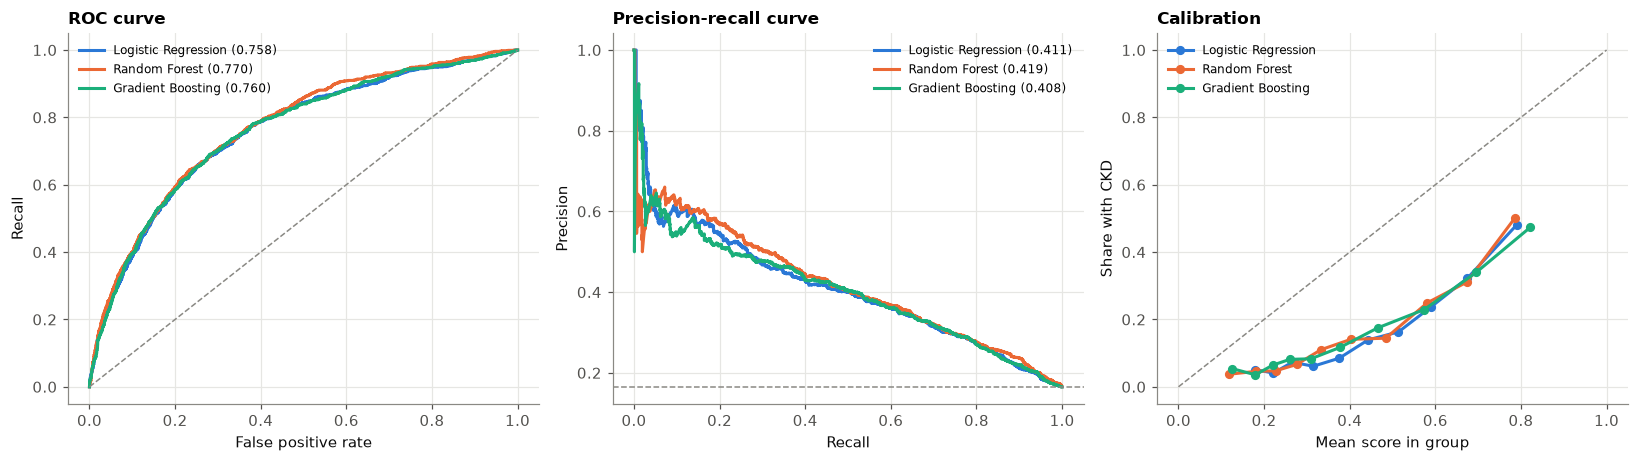

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for name, color in model_colors.items():
    fpr, tpr, _ = roc_curve(y_train, oof_proba[name])
    axes[0].plot(fpr, tpr, color=color, linewidth=2, label=f"{name} ({fold_scores[name]['roc_auc'].mean():.3f})")
    precision, recall, _ = precision_recall_curve(y_train, oof_proba[name])
    axes[1].plot(recall, precision, color=color, linewidth=2, label=f"{name} ({fold_scores[name]['pr_auc'].mean():.3f})")
    observed, predicted = calibration_curve(y_train, oof_proba[name], n_bins=10, strategy="quantile")
    axes[2].plot(predicted, observed, "o-", color=color, linewidth=2, markersize=5, label=name)
axes[0].plot([0, 1], [0, 1], color=plot_style.AXIS, linestyle="--", linewidth=1)
axes[0].set(title="ROC curve", xlabel="False positive rate", ylabel="Recall")
axes[1].axhline(y_train.mean(), color=plot_style.AXIS, linestyle="--", linewidth=1)
axes[1].set(title="Precision-recall curve", xlabel="Recall", ylabel="Precision")
axes[2].plot([0, 1], [0, 1], color=plot_style.AXIS, linestyle="--", linewidth=1)
axes[2].set(title="Calibration", xlabel="Mean score in group", ylabel="Share with CKD")
for ax in axes:
    ax.legend(loc="best", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "nhanes_09_curves.png")
plt.show()

**Finding:** The three ROC curves lie on top of each other, which matches the table: the models rank patients almost the same way. The precision-recall curves start well above the prevalence line (0.165) and fall toward it as recall rises. At the recall levels a screening tool needs (about 0.8), precision is around 0.25 to 0.3, so roughly one in three or four referred people would have CKD.

The calibration curves sit well below the diagonal for all three models: a score of 0.8 corresponds to an observed CKD rate of about 0.5. This is expected, because `class_weight="balanced"` makes the models treat the rare CKD cases as if they were as common as non-CKD cases, which pushes every score up.

**Action:** the raw score must not be shown to users as a percentage risk. The app shows the referral decision (which uses the tuned threshold, so it is not affected by calibration) and the observed CKD rate for patients with similar scores (section 9).

Confusion matrices from the out-of-fold predictions, each at its own tuned threshold. Rows are the true class and columns are the prediction.

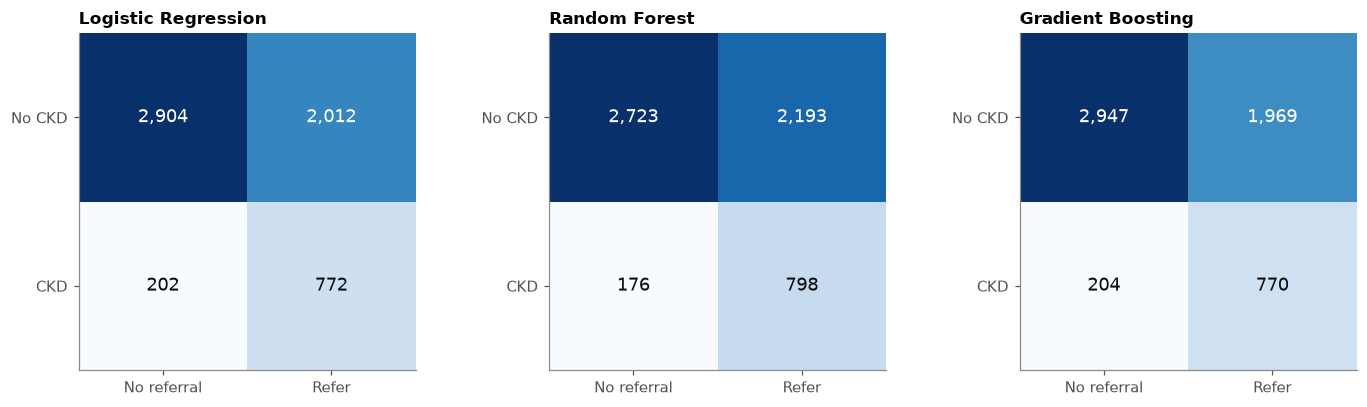

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, name in zip(axes, model_colors):
    matrix = confusion_matrix(y_train, oof_pred[name])
    ax.imshow(matrix, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{matrix[i, j]:,}", ha="center", va="center", fontsize=12,
                    color="white" if matrix[i, j] > matrix.max() / 2 else plot_style.TEXT)
    ax.set_xticks([0, 1], ["No referral", "Refer"])
    ax.set_yticks([0, 1], ["No CKD", "CKD"])
    ax.grid(False)
    ax.set_title(name)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "nhanes_10_confusion_cv.png")
plt.show()

**Finding:** At their tuned thresholds the three models make a similar trade: they catch about 79 to 82% of the CKD cases and refer roughly 40 to 45% of the people without CKD. Random Forest catches the most CKD cases (recall 0.819) at the cost of slightly more referrals of people without CKD (specificity 0.554).

**Action:** none. This is the trade that F2 asks for: a missed case is weighted more heavily than an extra blood test.

## 7. Error analysis for the selected model (training data, out-of-fold)

Which CKD patients does the model miss? I split recall by **why** each person was labeled CKD (low eGFR, albuminuria only, or both) and by age group. Then I look at which features the model relies on, using permutation importance: shuffle one feature at a time and measure how much the ROC-AUC drops. This is done on the training data only.

In [9]:
analysis = train.assign(proba=oof_proba[selected], pred=oof_pred[selected])
cases = analysis[analysis["ckd"] == 1]
reason_for_label = np.select(
    [(cases["low_egfr"] == 1) & (cases["albuminuria"] == 1), cases["low_egfr"] == 1],
    ["both", "low eGFR only"], default="albuminuria only")
by_reason = cases.groupby(reason_for_label)["pred"].agg(cases="size", recall="mean")

age_band = pd.cut(cases["age"], bins=[19, 39, 59, 80], labels=["20-39", "40-59", "60-80"])
by_age = cases.groupby(age_band, observed=True)["pred"].agg(cases="size", recall="mean")
print("Recall by reason for the CKD label:")
print(by_reason.round(3))
print("\nRecall by age group:")
print(by_age.round(3))

Recall by reason for the CKD label:
                  cases  recall
albuminuria only    617   0.736
both                117   0.983
low eGFR only       240   0.954

Recall by age group:
       cases  recall
age                 
20-39    122   0.311
40-59    242   0.694
60-80    610   0.970


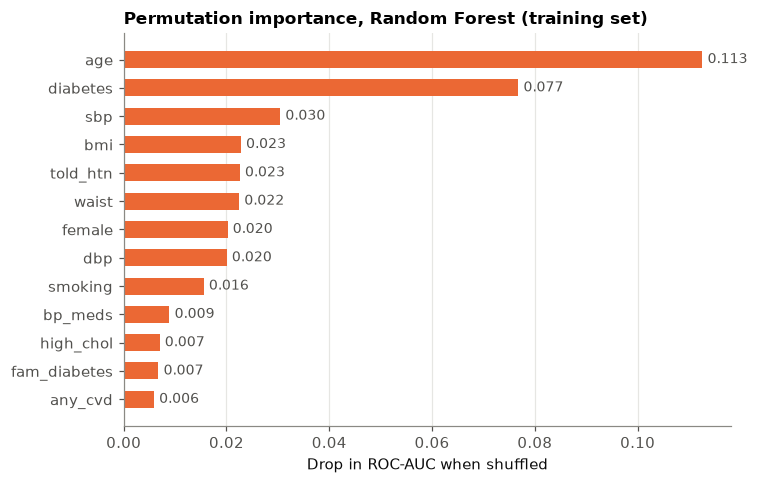

In [10]:
final_model = searches[selected].best_estimator_
importance = permutation_importance(final_model, X_train, y_train, scoring="roc_auc",
                                    n_repeats=10, random_state=modeling.RANDOM_STATE)
importance = pd.Series(importance.importances_mean, index=nhanes.FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(importance.index, importance.values, color=model_colors[selected], height=0.6)
for y, value in enumerate(importance.values):
    ax.text(max(value, 0) + 0.001, y, f"{value:.3f}", va="center", fontsize=9, color=plot_style.TEXT_SECONDARY)
ax.set(title=f"Permutation importance, {selected} (training set)", xlabel="Drop in ROC-AUC when shuffled")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "nhanes_11_importance.png")
plt.show()

**Finding:** The model catches almost all patients whose CKD shows up as low kidney function: recall is 0.954 for low eGFR only and 0.983 when both criteria are met. It misses many more of the albuminuria-only patients (recall 0.736), who make up 617 of the 974 training cases. Age shows the same pattern even more strongly: recall is 0.970 for ages 60 to 80, 0.694 for 40 to 59, and only 0.311 for 20 to 39.

These two results are connected. Low-eGFR CKD is concentrated in older people (EDA section 12), partly because the eGFR equation itself contains age, and age is by far the most important feature here (shuffling it lowers ROC-AUC by 0.113). Diabetes is second (0.077), then systolic blood pressure (0.030). Most other features add a little each.

**Action:** this goes into the paper as the main limitation of a pre-lab model: it mainly finds older patients and patients with diabetes, and it misses most young adults with CKD and many people whose only sign is albuminuria. The app's "About the model" section states that a "no referral" result does not rule out CKD.

## 8. Final test: run once

Everything above used the training data only. The selected model, refit on all 5,890 training rows with its tuned threshold, is now scored **once** on the 1,473 test rows. The two baselines are scored on the same rows for comparison. Nothing in the model or threshold is changed after this point.

In [11]:
test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = final_model.predict(X_test)

test_results = {
    selected: modeling.score_predictions(y_test, test_pred, test_proba),
    "Refer everyone": modeling.score_predictions(y_test, np.ones(len(y_test), dtype=int)),
    "Risk-factor rule": modeling.score_predictions(y_test, risk_factor_rule(X_test)),
}
test_table = pd.DataFrame(test_results).T.round(3)
test_table.to_csv(MODEL_DIR / "test_results.csv")
print(f"Threshold used: {final_model.best_threshold_:.3f}")
test_table

Threshold used: 0.320


,f2,recall,precision,specificity,f1,accuracy,roc_auc,pr_auc,brier
Random Forest,0.586,0.864,0.256,0.504,0.395,0.563,0.773,0.407,0.183
Refer everyone,0.497,1.000,0.165,0.000,0.283,0.165,NaN,NaN,NaN
Risk-factor rule,0.583,0.852,0.257,0.515,0.395,0.570,NaN,NaN,NaN


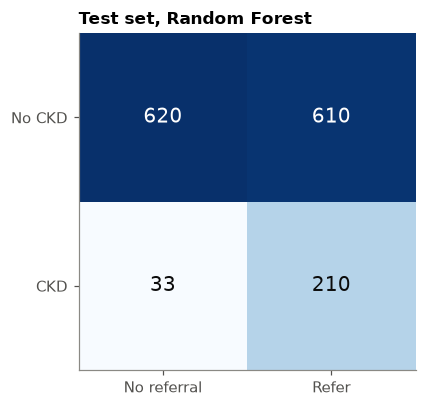

Caught 210 of 243 CKD cases, missed 33. Referred 820 of 1473 people, 610 of them without CKD.


In [12]:
matrix = confusion_matrix(y_test, test_pred)
fig, ax = plt.subplots(figsize=(4.5, 3.8))
ax.imshow(matrix, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{matrix[i, j]:,}", ha="center", va="center", fontsize=13,
                color="white" if matrix[i, j] > matrix.max() / 2 else plot_style.TEXT)
ax.set_xticks([0, 1], ["No referral", "Refer"])
ax.set_yticks([0, 1], ["No CKD", "CKD"])
ax.grid(False)
ax.set_title(f"Test set, {selected}")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "nhanes_12_confusion_test.png")
plt.show()

tn, fp, fn, tp = matrix.ravel()
print(f"Caught {tp} of {tp + fn} CKD cases, missed {fn}. Referred {tp + fp} of {len(y_test)} people, {fp} of them without CKD.")

**Finding:** On the 1,473 unseen test participants, the Random Forest gets F2 = 0.586, recall 0.864, specificity 0.504 and ROC-AUC 0.773. These are close to its cross-validation results (F2 0.580, ROC-AUC 0.770), so the model did not overfit the training data. Recall is a bit higher than in cross-validation because the final model, trained on all the training data, ended up with a slightly lower threshold (0.320, against a mean of 0.361 across the folds).

In practice, it caught 210 of 243 CKD cases and missed 33. It referred 820 people, of whom 610 did not have CKD. The risk-factor rule on the same people gets F2 = 0.583 (recall 0.852, specificity 0.515), so the test confirms the cross-validation result: the model and the rule perform about the same on the primary metric.

**Action:** none. This is the only time the test set is used, and these are the results reported in the paper.

### 8.1 Subgroup check: Non-Hispanic Asian participants

The closest available proxy for an Asian population. This is not a Filipino population, and the group is small, so this is a rough check only.

In [13]:
asian = (test["RIDRETH3"] == 6).to_numpy()
subgroup = modeling.score_predictions(y_test[asian], test_pred[asian], test_proba[asian])
print(f"Non-Hispanic Asian test participants: {asian.sum()}, CKD cases: {y_test[asian].sum()}")
pd.Series(subgroup).round(3).to_frame("Non-Hispanic Asian")

Non-Hispanic Asian test participants: 175, CKD cases: 26


,Non-Hispanic Asian
f2,0.574
recall,0.808
precision,0.266
specificity,0.611
f1,0.400
accuracy,0.640
roc_auc,0.795
pr_auc,0.382
brier,0.154


**Finding:** The test set has 175 Non-Hispanic Asian participants with 26 CKD cases. In this group, the model gets recall 0.808 (21 of 26), specificity 0.611 and ROC-AUC 0.795, similar to the full test set. With only 26 cases, one more or one fewer missed patient changes recall by about 4 points, so this only shows that nothing obviously breaks for this group. It is not evidence that the model works for Filipino patients.

**Action:** reported as a rough check, with this caveat, in the paper and in the app's limitations.

## 9. Saving the pipeline for the app

The saved object is the whole fitted pipeline: imputation, scaling, encoding, the model, and the tuned threshold. The app loads this file and nothing else, so it uses exactly the preprocessing that was used in training.

The model card also stores a **risk table** built from the out-of-fold predictions: for ten equal-sized groups of training patients with similar scores, the share that really had CKD. Because `class_weight="balanced"` makes the raw scores higher than the true risk (section 6), the app shows this observed share instead of the raw score as a percentage.

In [14]:
joblib.dump(final_model, MODEL_DIR / "ckd_screening_pipeline.joblib")

risk = modeling.risk_table(oof_proba[selected], y_train)
card = {
    "model": selected,
    "hyperparameters": {k.replace("estimator__model__", ""): v for k, v in searches[selected].best_params_.items()},
    "threshold": float(final_model.best_threshold_),
    "features": nhanes.FEATURES,
    "numeric_features": nhanes.NUMERIC_FEATURES,
    "binary_features": nhanes.BINARY_FEATURES,
    "categorical_features": nhanes.CATEGORICAL_FEATURES,
    "training_rows": int(len(train)),
    "training_prevalence": float(y_train.mean()),
    "random_state": modeling.RANDOM_STATE,
    "sklearn_version": sklearn.__version__,
    "cv_mean": {m: float(fold_scores[selected][m].mean()) for m in modeling.METRICS},
    "cv_sd": {m: float(fold_scores[selected][m].std()) for m in modeling.METRICS},
    "test": {m: float(v) for m, v in test_results[selected].items()},
    "risk_table": risk.round(4).to_dict("records"),
}
(MODEL_DIR / "model_card.json").write_text(json.dumps(card, indent=2))

# check the saved file gives the same predictions as the model in memory
reloaded = joblib.load(MODEL_DIR / "ckd_screening_pipeline.joblib")
print("Reloaded predictions identical:", np.array_equal(reloaded.predict_proba(X_test), final_model.predict_proba(X_test)))
print(f"File size: {(MODEL_DIR / 'ckd_screening_pipeline.joblib').stat().st_size / 1e6:.1f} MB")
risk.round(3)

Reloaded predictions identical: True
File size: 5.4 MB


,low,high,people,observed_rate
0,0.043,0.155,589,0.037
1,0.155,0.203,589,0.046
2,0.204,0.252,589,0.048
3,0.252,0.303,589,0.066
4,0.303,0.365,589,0.110
5,0.365,0.442,589,0.141
6,0.442,0.530,589,0.144
7,0.530,0.630,589,0.250
8,0.630,0.720,589,0.311
9,0.720,0.901,589,0.501


**Finding:** The saved file reloads and gives exactly the same predictions as the model in memory, and it is 5.4 MB, small enough for the repository and for Streamlit Cloud. The risk table shows how much the raw score overstates risk: the 10% of training patients with the highest scores (0.72 to 0.90) had CKD 50.1% of the time, and the 10% with the lowest scores had CKD 3.7% of the time. That is still a useful spread. Testing the top-scored tenth finds CKD at three times the overall rate (16.5%).

**Action:** the app reads the threshold and the risk table from `model_card.json`, so it shows the same referral rule and the same observed rates reported here.

## 10. Summary

| Question | Answer |
|---|---|
| Do the three models differ? | No. CV F2 0.578 to 0.580, ROC-AUC 0.758 to 0.770, differences far smaller than the fold-to-fold spread |
| Which model was selected? | Random Forest, by the pre-registered tie-break rule (Gradient Boosting was ahead by less than one SD) |
| Does it beat referring everyone? (H3) | Yes. F2 0.580 vs 0.498 in CV, 0.586 vs 0.497 on test |
| Does it beat the risk-factor rule? | Not meaningfully. F2 0.580 vs 0.576 in CV, 0.586 vs 0.583 on test |
| Final test result | F2 0.586, recall 0.864, specificity 0.504, ROC-AUC 0.773. Caught 210 of 243 CKD cases |
| Who does it miss? | Younger adults (recall 0.31 at ages 20 to 39) and albuminuria-only CKD (recall 0.74) |
| Calibration | Raw scores overstate risk, so the app shows observed rates instead |

With only information available before a lab test, all three algorithms reach about the same ceiling, and that ceiling is close to what a simple risk-factor rule already achieves. The model's practical advantage over the rule is that it gives a graded score instead of a yes/no answer: when a health unit can only test some people, the highest-scored tenth has a CKD rate three times the average. Compare this with the UCI ablation, where the same three algorithms reach 99% only when given the lab values that define CKD.

## 11. Post-hoc analyses after peer review

Everything in this section was added on 13 October 2026, after the final test, because a peer reviewer asked three fair questions:

1. Does the model add value over the risk-factor rule when both refer the same number of people?
2. Is the small F2 gap on the test set (0.586 vs 0.583) real, or just noise?
3. A clinic is usually limited by how many test kits it has, not by a score threshold. How do the model and the rule compare when only the top K people can be tested?

These are **post-hoc** analyses. They use the saved pipeline (the same file the app loads) and the test rows, but they do not change the selected model, its threshold, or any result above. The change is recorded in Section 8 of `documentation/preregistration.md`.

I also add a stronger baseline, a **points rule**: how many of the rule's four risk factors a person has (0 to 4). The yes/no rule cannot rank people, but the points rule can, so it is the fair comparison when ranking matters.

In [15]:
# This section only needs the saved pipeline and the test rows, so it runs on its own after the setup cells
from sklearn.metrics import fbeta_score

saved_model = joblib.load(MODEL_DIR / "ckd_screening_pipeline.joblib")
y = y_test.to_numpy()

test_score = saved_model.predict_proba(X_test)[:, 1]  # model score, higher means more likely CKD
model_refer = saved_model.predict(X_test)  # refer (1) or not (0) at the 0.32 threshold
rule_refer = risk_factor_rule(X_test).to_numpy()  # the yes/no risk-factor rule from section 2

# points rule: how many of the rule's 4 risk factors a person has (0 to 4), so the rule can rank people too
rule_points = ((X_test["diabetes"] == "yes").astype(int) + (X_test["told_htn"] == 1).astype(int)
               + (X_test["any_cvd"] == 1).astype(int) + (X_test["age"] >= 60).astype(int)).to_numpy()

print(f"Test rows: {len(y)}, CKD cases: {y.sum()}")
print("People with 0, 1, 2, 3, 4 risk factors:", np.bincount(rule_points))

Test rows: 1473, CKD cases: 243
People with 0, 1, 2, 3, 4 risk factors: [669 372 269 128  35]


### 11.1 Same number of referrals

The rule refers a fixed group of people. To compare fairly, the model gets exactly the same number of referrals: the people with its highest scores. Look at the "CKD caught" column.

In [16]:
n_rule = int(rule_refer.sum())  # how many people the rule refers

# give the model exactly the same number of referrals: the n_rule people with its highest scores
model_top = np.zeros(len(y), dtype=int)
model_top[np.argsort(-test_score)[:n_rule]] = 1


def referral_summary(pred):
    caught = int((pred * y).sum())
    return {"referred": int(pred.sum()), "CKD caught": caught,
            "recall": caught / y.sum(), "precision": caught / pred.sum()}


same_capacity = pd.DataFrame({
    "Random Forest, threshold 0.32": referral_summary(model_refer),
    f"Random Forest, top {n_rule}": referral_summary(model_top),
    "Risk-factor rule": referral_summary(rule_refer),
}).T
same_capacity.round(3)

,referred,CKD caught,recall,precision
"Random Forest, threshold 0.32",820.0,210.0,0.864,0.256
"Random Forest, top 804",804.0,208.0,0.856,0.259
Risk-factor rule,804.0,207.0,0.852,0.257


**Finding:** At the same number of referrals (804), the model and the rule find almost the same people: 208 vs 207 of the 243 CKD cases. At its own threshold of 0.32 the model refers 16 more people and finds 2 more cases.

**Action:** at the rule's referral volume the model adds no real value. Any value has to come from ranking, which the next part checks.

### 11.2 Cases found at each testing capacity

For every possible number of tests, from 0 up to everyone, this counts how many CKD cases are found when people are tested in order of their score. People with the same score (for example, everyone with 2 risk factors) are counted in proportion with `modeling.cases_caught`. A higher line is better. The dotted line is what testing people in random order would find.

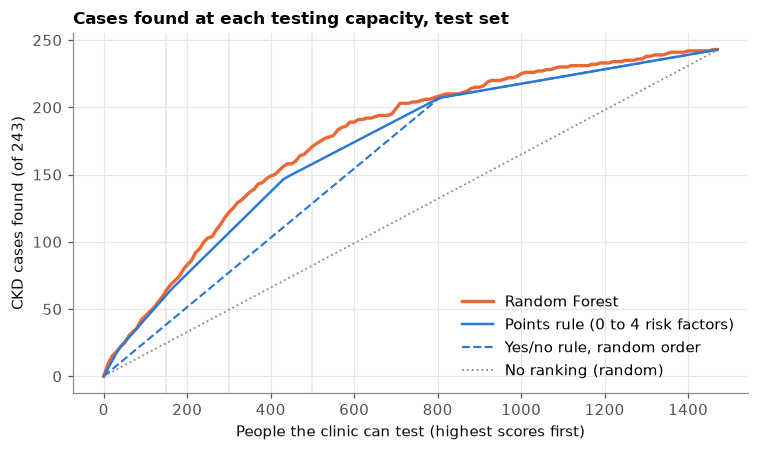

,Random Forest,Points rule (0 to 4 risk factors),"Yes/no rule, random order"
people tested,,,
150,64.0,60.4,38.6
300,122.0,106.8,77.2
500,171.0,158.0,128.7
804,208.0,207.0,207.0


In [17]:
capacities = np.arange(0, len(y) + 1, 10)  # number of people a clinic can test
rankers = {
    "Random Forest": test_score,
    "Points rule (0 to 4 risk factors)": rule_points,
    "Yes/no rule, random order": rule_refer,
}
curves = {name: [modeling.cases_caught(s, y, k) for k in capacities] for name, s in rankers.items()}
curves["No ranking (random)"] = [k * y.mean() for k in capacities]

fig, ax = plt.subplots(figsize=(7, 4.2))
styles = {
    "Random Forest": dict(color=plot_style.CKD, lw=2.2),
    "Points rule (0 to 4 risk factors)": dict(color=plot_style.NO_CKD, lw=1.6),
    "Yes/no rule, random order": dict(color=plot_style.NO_CKD, lw=1.4, ls="--"),
    "No ranking (random)": dict(color=plot_style.AXIS, lw=1.2, ls=":"),
}
for name, style in styles.items():
    ax.plot(capacities, curves[name], label=name, **style)
for k in [150, 300, 500]:
    ax.axvline(k, color=plot_style.GRID, lw=1, zorder=0)
ax.set_xlabel("People the clinic can test (highest scores first)")
ax.set_ylabel(f"CKD cases found (of {y.sum()})")
ax.set_title("Cases found at each testing capacity, test set")
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "nhanes_13_capacity.png")
plt.show()

checkpoints = [150, 300, 500, n_rule]
pd.DataFrame({name: [round(modeling.cases_caught(s, y, k), 1) for k in checkpoints] for name, s in rankers.items()},
             index=pd.Index(checkpoints, name="people tested"))

**Finding:** The model's line sits above both rules for most capacities below about 800 tests. With 300 tests it finds 122 cases, against 107 for the points rule and 77 for the yes/no rule picked in random order. With 150 tests the model and the points rule are close (64 vs 60). At about 800 tests all three meet, which matches 11.1.

**Action:** the model's value is in ranking, when a clinic cannot test everyone the rule would refer. That is the claim the paper should make, not a better F2.

### 11.3 Confidence intervals

One test set gives one number per comparison. The bootstrap estimates how much those numbers would move with a different sample of 1,473 people. If a 95% interval includes zero, the difference could be noise.

In [18]:
# Bootstrap: resample the test people with replacement 2,000 times and recompute each difference.
# The middle 95% of those differences is the 95% confidence interval.
rng = np.random.default_rng(modeling.RANDOM_STATE)
f2_diff, caught_diff = [], {k: [] for k in [150, 300, 500]}
for _ in range(2000):
    i = rng.integers(0, len(y), len(y))
    f2_diff.append(fbeta_score(y[i], model_refer[i], beta=2) - fbeta_score(y[i], rule_refer[i], beta=2))
    for k in caught_diff:
        caught_diff[k].append(modeling.cases_caught(test_score[i], y[i], k) - modeling.cases_caught(rule_points[i], y[i], k))


def interval(values, decimals):
    low, high = np.percentile(values, [2.5, 97.5])
    return f"{low:.{decimals}f} to {high:.{decimals}f}"


observed_f2 = fbeta_score(y, model_refer, beta=2) - fbeta_score(y, rule_refer, beta=2)
rows = {"F2: Random Forest minus yes/no rule": (f"{observed_f2:.3f}", interval(f2_diff, 3))}
for k, values in caught_diff.items():
    observed = modeling.cases_caught(test_score, y, k) - modeling.cases_caught(rule_points, y, k)
    rows[f"Cases found in top {k}: Random Forest minus points rule"] = (f"{observed:.1f}", interval(values, 1))
pd.DataFrame(rows, index=["difference", "95% CI"]).T

,difference,95% CI
F2: Random Forest minus yes/no rule,0.003,-0.017 to 0.024
Cases found in top 150: Random Forest minus points rule,3.6,-5.9 to 13.1
Cases found in top 300: Random Forest minus points rule,15.2,3.9 to 25.3
Cases found in top 500: Random Forest minus points rule,13.0,2.4 to 22.6


**Finding:** The F2 difference against the yes/no rule is 0.003, with a 95% CI of -0.017 to 0.024, so on F2 the model and the rule are tied. Against the points rule, the model finds 15.2 more cases with 300 tests (95% CI 3.9 to 25.3) and 13.0 more with 500 tests (2.4 to 22.6); both intervals stay above zero. With 150 tests the interval crosses zero (-5.9 to 13.1).

**Action:** report the gain as modest and limited to capacities of roughly 300 to 500 tests per 1,473 people screened (about 20 to 35% of them).

### 11.4 Recall by age on the test set

The reviewer suggested a stop rule for local validation based on recall in people under 50. Before writing one, I check where the current model already stands on this test set.

In [19]:
age_group = pd.cut(X_test["age"], bins=[19, 49, 80], labels=["20 to 49", "50 to 80"])
cases = pd.Series(y).groupby(age_group, observed=True).sum()
by_age = pd.DataFrame({
    "CKD cases": cases,
    "Random Forest recall": pd.Series(model_refer * y).groupby(age_group, observed=True).sum() / cases,
    "Risk-factor rule recall": pd.Series(rule_refer * y).groupby(age_group, observed=True).sum() / cases,
})
by_age.round(3)

,CKD cases,Random Forest recall,Risk-factor rule recall
age,,,
20 to 49,51,0.471,0.431
50 to 80,192,0.969,0.964


**Finding:** Among the 51 test cases aged 20 to 49, the model catches 47% (the rule 43%). From age 50 it catches 97%. The model already falls short of a 0.70 recall target for under-50s on US data.

**Action:** the stop rule in the paper has to treat under-50s as a known gap that needs another route, such as a urine dipstick, instead of setting a target the model already fails.

### 11.5 Summary of the post-hoc analyses

| Question | Answer |
|---|---|
| Same number of referrals as the rule | Tied: 208 vs 207 cases found with 804 referrals |
| F2 difference vs the yes/no rule | 0.003 (95% CI -0.017 to 0.024), tied |
| Ranking vs the points rule, 300 tests | 15.2 more cases (95% CI 3.9 to 25.3) |
| Ranking vs the points rule, 500 tests | 13.0 more cases (95% CI 2.4 to 22.6) |
| Ranking vs the points rule, 150 tests | 3.6 more cases (95% CI -5.9 to 13.1), not clear |
| Recall under 50 | 0.47 (rule 0.43) |

The model is not a better classifier than the rule. It is a slightly better ranker, and that only matters when there are fewer tests than people the rule would refer.